In [1]:
import pandas as pd

from google.colab import files
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)), parse_dates=["month"], dtype={"account_id": str})

print(df.shape)
print(df["month"].min(), "->", df["month"].max())
print(df["account_id"].nunique(), "accounts")
df.head(8)

Saving features_targets.csv to features_targets.csv
(2100, 27)
2022-03-01 00:00:00 -> 2022-09-01 00:00:00
300 accounts


,account_id,month,balance_lag1,balance_lag2,balance_lag3,balance_mean_3m,balance_std_3m,balance_change,credit_lag1,debit_lag1,...,spend_food_lag1,spend_travel_lag1,spend_shopping_lag1,spend_bills_lag1,spend_health_education_lag1,spend_cash_transfers_lag1,spend_other_lag1,month_of_year,days_in_month,target_balance
0,501893368,2022-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,31,0.00
1,501893368,2022-04-01,0.00,NaN,NaN,0.000000,NaN,NaN,0.0,0.00,...,0.0,0.0,0.00,0.00,0.0,0.0,0.0,4,30,0.00
2,501893368,2022-05-01,0.00,0.00,NaN,0.000000,0.000000,0.00,0.0,0.00,...,0.0,0.0,0.00,0.00,0.0,0.0,0.0,5,31,-42.55
3,501893368,2022-06-01,-42.55,0.00,0.00,-14.183333,24.566254,-42.55,0.0,42.55,...,0.0,0.0,0.00,42.55,0.0,0.0,0.0,6,30,-42.55
4,501893368,2022-07-01,-42.55,-42.55,0.00,-28.366667,24.566254,0.00,0.0,0.00,...,0.0,0.0,0.00,0.00,0.0,0.0,0.0,7,31,-46.56
5,501893368,2022-08-01,-46.56,-42.55,-42.55,-43.886667,2.315175,-4.01,0.0,4.01,...,0.0,0.0,4.01,0.00,0.0,0.0,0.0,8,31,-46.56
6,501893368,2022-09-01,-46.56,-46.56,-42.55,-45.223333,2.315175,0.00,0.0,0.00,...,0.0,0.0,0.00,0.00,0.0,0.0,0.0,9,30,-659.59
7,504781482,2022-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,31,0.00


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2100 entries, 0 to 2099
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   account_id                   2100 non-null   object        
 1   month                        2100 non-null   datetime64[ns]
 2   balance_lag1                 1800 non-null   float64       
 3   balance_lag2                 1500 non-null   float64       
 4   balance_lag3                 1200 non-null   float64       
 5   balance_mean_3m              1800 non-null   float64       
 6   balance_std_3m               1500 non-null   float64       
 7   balance_change               1500 non-null   float64       
 8   credit_lag1                  1800 non-null   float64       
 9   debit_lag1                   1800 non-null   float64       
 10  net_lag1                     1800 non-null   float64       
 11  credit_avg_3m                1800 non-null 

In [3]:
pd.set_option("display.max_columns", 30)
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
month,2100,2022-05-31 20:34:17.142857216,2022-03-01 00:00:00,2022-04-01 00:00:00,2022-06-01 00:00:00,2022-08-01 00:00:00,2022-09-01 00:00:00,NaN
balance_lag1,1800.0,-1114.222139,-9830.42,-1496.58,-667.845,-206.7,946.39,1375.721397
balance_lag2,1500.0,-941.603573,-9473.63,-1277.3,-550.31,-140.01,946.39,1230.336923
balance_lag3,1200.0,-798.9309,-8878.29,-983.095,-472.01,-76.1075,946.39,1116.838364
balance_mean_3m,1800.0,-878.502448,-9394.113333,-1155.418333,-530.268333,-150.855,711.1,1132.542735
balance_std_3m,1500.0,327.202765,0.0,22.72831,182.726113,376.13891,3736.137515,496.372242
balance_change,1500.0,-323.145467,-6471.18,-385.1625,-65.065,0.0,1329.75,683.623203
credit_lag1,1800.0,14.685544,0.0,0.0,0.0,0.0,3516.27,117.20258
debit_lag1,1800.0,344.238039,0.0,0.0,83.68,402.575,6471.18,682.596949
net_lag1,1800.0,-329.552494,-6471.18,-397.8175,-69.57,0.0,1329.75,683.839828


In [4]:
df = df.drop(columns=["n_accounts", "spend_other_lag1"])
print(df.shape)

(2100, 25)


In [5]:

df = df[df["month"] > "2022-03-01"].reset_index(drop=True)
print(df.shape)

(1800, 25)


In [6]:
df.head()

,account_id,month,balance_lag1,balance_lag2,balance_lag3,balance_mean_3m,balance_std_3m,balance_change,credit_lag1,debit_lag1,net_lag1,credit_avg_3m,debit_avg_3m,net_avg_3m,txn_count_lag1,merchant_count_lag1,spend_food_lag1,spend_travel_lag1,spend_shopping_lag1,spend_bills_lag1,spend_health_education_lag1,spend_cash_transfers_lag1,month_of_year,days_in_month,target_balance
0,501893368,2022-04-01,0.00,NaN,NaN,0.000000,NaN,NaN,0.0,0.00,0.00,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,4,30,0.00
1,501893368,2022-05-01,0.00,0.00,NaN,0.000000,0.000000,0.00,0.0,0.00,0.00,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,5,31,-42.55
2,501893368,2022-06-01,-42.55,0.00,0.00,-14.183333,24.566254,-42.55,0.0,42.55,-42.55,0.0,14.183333,-14.183333,1.0,1.0,0.0,0.0,0.00,42.55,0.0,0.0,6,30,-42.55
3,501893368,2022-07-01,-42.55,-42.55,0.00,-28.366667,24.566254,0.00,0.0,0.00,0.00,0.0,14.183333,-14.183333,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,7,31,-46.56
4,501893368,2022-08-01,-46.56,-42.55,-42.55,-43.886667,2.315175,-4.01,0.0,4.01,-4.01,0.0,15.520000,-15.520000,1.0,1.0,0.0,0.0,4.01,0.00,0.0,0.0,8,31,-46.56


In [7]:
num = df.select_dtypes("number")
corr = num.corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if corr.loc[a, b] > 0.95]
pd.DataFrame(pairs, columns=["feature_1", "feature_2", "corr"])

,feature_1,feature_2,corr
0,balance_lag1,balance_mean_3m,0.952
1,balance_lag2,balance_mean_3m,0.969
2,balance_change,debit_lag1,0.992
3,balance_change,net_lag1,1.000
4,debit_lag1,net_lag1,0.985
5,debit_avg_3m,net_avg_3m,0.971
6,txn_count_lag1,merchant_count_lag1,1.000


In [8]:
df = df.drop(columns=["balance_change", "merchant_count_lag1"])
print(df.shape)

(1800, 23)


In [9]:
df.head(8)

,account_id,month,balance_lag1,balance_lag2,balance_lag3,balance_mean_3m,balance_std_3m,credit_lag1,debit_lag1,net_lag1,credit_avg_3m,debit_avg_3m,net_avg_3m,txn_count_lag1,spend_food_lag1,spend_travel_lag1,spend_shopping_lag1,spend_bills_lag1,spend_health_education_lag1,spend_cash_transfers_lag1,month_of_year,days_in_month,target_balance
0,501893368,2022-04-01,0.00,NaN,NaN,0.000000,NaN,0.0,0.00,0.00,0.0,0.000000,0.000000,0.0,0.00,0.0,0.00,0.00,0.0,0.0,4,30,0.00
1,501893368,2022-05-01,0.00,0.00,NaN,0.000000,0.000000,0.0,0.00,0.00,0.0,0.000000,0.000000,0.0,0.00,0.0,0.00,0.00,0.0,0.0,5,31,-42.55
2,501893368,2022-06-01,-42.55,0.00,0.00,-14.183333,24.566254,0.0,42.55,-42.55,0.0,14.183333,-14.183333,1.0,0.00,0.0,0.00,42.55,0.0,0.0,6,30,-42.55
3,501893368,2022-07-01,-42.55,-42.55,0.00,-28.366667,24.566254,0.0,0.00,0.00,0.0,14.183333,-14.183333,0.0,0.00,0.0,0.00,0.00,0.0,0.0,7,31,-46.56
4,501893368,2022-08-01,-46.56,-42.55,-42.55,-43.886667,2.315175,0.0,4.01,-4.01,0.0,15.520000,-15.520000,1.0,0.00,0.0,4.01,0.00,0.0,0.0,8,31,-46.56
5,501893368,2022-09-01,-46.56,-46.56,-42.55,-45.223333,2.315175,0.0,0.00,0.00,0.0,1.336667,-1.336667,0.0,0.00,0.0,0.00,0.00,0.0,0.0,9,30,-659.59
6,504781482,2022-04-01,0.00,NaN,NaN,0.000000,NaN,0.0,0.00,0.00,0.0,0.000000,0.000000,0.0,0.00,0.0,0.00,0.00,0.0,0.0,4,30,-140.01
7,504781482,2022-05-01,-140.01,0.00,NaN,-70.005000,99.002020,0.0,140.01,-140.01,0.0,70.005000,-70.005000,2.0,137.28,0.0,0.00,2.73,0.0,0.0,5,31,-140.01


            target_mean  target_median  change_mean  quiet_pct
month                                                         
2022-04-01       -640.0         -401.0       -278.4       33.7
2022-05-01       -951.3         -561.3       -311.3       40.0
2022-06-01      -1242.9         -861.7       -291.6       33.3
2022-07-01      -1512.3        -1128.9       -269.4       39.3
2022-08-01      -1977.3        -1467.2       -465.0       27.7
2022-09-01      -2322.2        -1779.3       -344.9       37.3


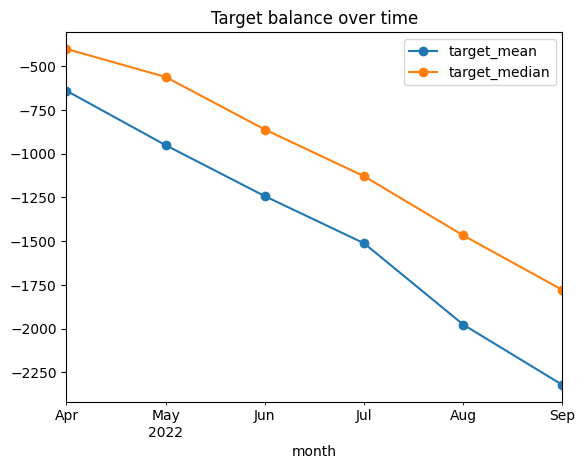

In [10]:
import matplotlib.pyplot as plt

df["change"] = df["target_balance"] - df["balance_lag1"]     # how much the balance moved THIS month

by_month = df.groupby("month").agg(
    target_mean=("target_balance", "mean"),
    target_median=("target_balance", "median"),
    change_mean=("change", "mean"),
    quiet_pct=("change", lambda c: round((c == 0).mean() * 100, 1)),   # % accounts that didn't move
)
print(by_month.round(1))

by_month[["target_mean", "target_median"]].plot(marker="o", title="Target balance over time")
plt.show()

type
active (4-6)     187
regular (2-3)    109
quiet (0-1)        4
Name: count, dtype: int64
               count   mean    std     min    25%    50%    75%    max
type                                                                  
quiet (0-1)      4.0  -70.9  163.6  -313.1  -88.6   -8.5    9.1   46.5
regular (2-3)  109.0 -225.7  209.9  -925.3 -269.2 -161.5 -100.5   63.1
active (4-6)   187.0 -391.1  299.6 -1528.0 -493.2 -296.3 -196.9  442.6
accounts with a refund: 82


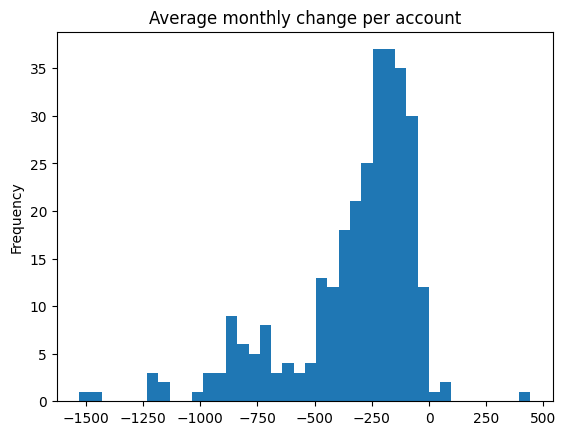

In [11]:

acc = df.groupby("account_id").agg(
    active_months=("change", lambda c: (c != 0).sum()),
    avg_change=("change", "mean"),
    has_refund=("credit_lag1", lambda c: (c > 0).any()),
)


acc["type"] = pd.cut(acc["active_months"], bins=[-1, 1, 3, 6],
                     labels=["quiet (0-1)", "regular (2-3)", "active (4-6)"])

print(acc["type"].value_counts())
print(acc.groupby("type", observed=True)["avg_change"].describe().round(1))
print("accounts with a refund:", acc["has_refund"].sum())

acc["avg_change"].plot.hist(bins=40, title="Average monthly change per account")
plt.show()

In [12]:
from sklearn.metrics import mean_absolute_error, r2_score

df = df.drop(columns=["change"])

train = df[df["month"] <= "2022-07-01"]
valid = df[df["month"] == "2022-08-01"]
test  = df[df["month"] == "2022-09-01"]
print(len(train), len(valid), len(test))

1200 300 300


In [13]:
def score(name, part, pred):
    y, lag1 = part["target_balance"], part["balance_lag1"]
    return {"model": name,
            "MAE": round(mean_absolute_error(y, pred), 1),
            "R2_level": round(r2_score(y, pred), 3),
            "R2_change": round(r2_score(y - lag1, pred - lag1), 3)}

results = [score("last month", valid, valid["balance_lag1"]),
           score("3-month average", valid, valid["balance_mean_3m"])]
pd.DataFrame(results)

,model,MAE,R2_level,R2_change
0,last month,480.2,0.645,-0.266
1,3-month average,751.5,0.448,-0.969


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

DROP_FOR_LINEAR = ["debit_lag1", "debit_avg_3m"]
FEATURES = [c for c in df.columns
            if c not in ["account_id", "month", "target_balance"] + DROP_FOR_LINEAR]

def prepare(part):
    X = part[FEATURES].copy()
    X["has_full_history"] = part["balance_lag3"].notna().astype(int)
    X = X.fillna(0)
    y_change = part["target_balance"] - part["balance_lag1"]
    return X, y_change

X_train, y_train = prepare(train)
X_valid, _ = prepare(valid)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)

linear = LinearRegression()
linear.fit(X_train_s, y_train)

pred_valid = valid["balance_lag1"] + linear.predict(X_valid_s)
results.append(score("linear", valid, pred_valid))
pd.DataFrame(results)

,model,MAE,R2_level,R2_change
0,last month,480.2,0.645,-0.266
1,3-month average,751.5,0.448,-0.969
2,linear,467.8,0.708,-0.040


In [15]:
print("avg move in train (Apr-Jul):", round(y_train.mean(), 1))
print("avg move guessed for Aug   :", round((pred_valid - valid["balance_lag1"]).mean(), 1))
print("avg move real in Aug       :", round((valid["target_balance"] - valid["balance_lag1"]).mean(), 1))

avg move in train (Apr-Jul): -287.7
avg move guessed for Aug   : -287.7
avg move real in Aug       : -465.0


In [16]:
TEST_MONTHS = ["2022-06-01", "2022-07-01", "2022-08-01"]
dev = df[df["month"] < "2022-09-01"]

def walk_forward(name, fit_predict):

    rows = []
    for m in TEST_MONTHS:
        tr = dev[dev["month"] < m]
        te = dev[dev["month"] == m]
        pred = fit_predict(tr, te)
        r = score(name, te, pred)
        r["month"] = m[:7]
        rows.append(r)
    return pd.DataFrame(rows)


def last_month(tr, te):
    return te["balance_lag1"]

def avg_3m(tr, te):
    return te["balance_mean_3m"]

def linear_model(tr, te):
    X_tr, y_tr = prepare(tr)
    X_te, _ = prepare(te)
    scaler = StandardScaler()
    model = LinearRegression().fit(scaler.fit_transform(X_tr), y_tr)
    return te["balance_lag1"] + model.predict(scaler.transform(X_te))

per_month = pd.concat([walk_forward("last month", last_month),
                       walk_forward("3-month average", avg_3m),
                       walk_forward("linear", linear_model)])
print(per_month)
per_month.groupby("model")[["MAE", "R2_level", "R2_change"]].mean().round(3)

             model    MAE  R2_level  R2_change    month
0       last month  315.4     0.782     -0.264  2022-06
1       last month  273.5     0.815     -0.221  2022-07
2       last month  480.2     0.645     -0.266  2022-08
0  3-month average  607.6     0.486     -1.975  2022-06
1  3-month average  576.9     0.599     -1.648  2022-07
2  3-month average  751.5     0.448     -0.969  2022-08
0           linear  379.7     0.813     -0.084  2022-06
1           linear  428.6     0.793     -0.368  2022-07
2           linear  467.8     0.708     -0.040  2022-08


,MAE,R2_level,R2_change
model,,,
3-month average,645.333,0.511,-1.531
last month,356.367,0.747,-0.250
linear,425.367,0.771,-0.164


In [17]:
print((6 - acc["active_months"]).value_counts().sort_index())

active_months
0     27
1     58
2    102
3     84
4     25
5      4
Name: count, dtype: int64


In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor


TREE_FEATURES = [c for c in df.columns if c not in ["account_id", "month", "target_balance"]]

def boosting(tr, te):
    model = HistGradientBoostingRegressor(
        loss="absolute_error",
        max_depth=3,
        learning_rate=0.05,
        max_iter=200,
        min_samples_leaf=20,
        random_state=0)
    model.fit(tr[TREE_FEATURES], tr["target_balance"] - tr["balance_lag1"])
    return te["balance_lag1"] + model.predict(te[TREE_FEATURES])

per_month = pd.concat([per_month[per_month["model"] != "boosting"],
                       walk_forward("boosting", boosting)])
per_month.groupby("model")[["MAE", "R2_level", "R2_change"]].mean().round(3).sort_values("MAE")

,MAE,R2_level,R2_change
model,,,
boosting,347.267,0.768,-0.136
last month,356.367,0.747,-0.250
linear,425.367,0.771,-0.164
3-month average,645.333,0.511,-1.531


In [19]:
per_month.pivot(index="month", columns="model", values="MAE").round(1)

model,3-month average,boosting,last month,linear
month,,,,
2022-06,607.6,305.0,315.4,379.7
2022-07,576.9,275.3,273.5,428.6
2022-08,751.5,461.5,480.2,467.8


In [20]:
df = df.sort_values(["account_id", "month"]).reset_index(drop=True)
g = df.groupby("account_id")

# 1. average past move (net_lag1 of row M = the move of month M-1)
df["move_avg_all"] = g["net_lag1"].transform(lambda s: s.expanding().mean())

# 2. share of past months with at least 1 transaction
df["active_share"] = g["txn_count_lag1"].transform(lambda s: (s > 0).expanding().mean())

# 3. quiet months in a row, just before this month
def quiet_streak(s):
    streak, out = 0, []
    for active in (s > 0):
        streak = 0 if active else streak + 1
        out.append(streak)
    return pd.Series(out, index=s.index)
df["quiet_streak"] = g["txn_count_lag1"].transform(quiet_streak)

df[df["account_id"] == "501893368"][["month", "net_lag1", "txn_count_lag1",
                                     "move_avg_all", "active_share", "quiet_streak"]]

,month,net_lag1,txn_count_lag1,move_avg_all,active_share,quiet_streak
0,2022-04-01,0.00,0.0,0.000000,0.000000,1
1,2022-05-01,0.00,0.0,0.000000,0.000000,2
2,2022-06-01,-42.55,1.0,-14.183333,0.333333,0
3,2022-07-01,0.00,0.0,-10.637500,0.250000,1
4,2022-08-01,-4.01,1.0,-9.312000,0.400000,0
5,2022-09-01,0.00,0.0,-7.760000,0.333333,1


In [21]:
NEW = ["move_avg_all", "active_share", "quiet_streak"]
dev = df[df["month"] < "2022-09-01"]

TREE_FEATURES = [c for c in df.columns
                 if c not in ["account_id", "month", "target_balance"] + NEW]
TREE_FEATURES_NEW = TREE_FEATURES + NEW

def boosting_new(tr, te):
    model = HistGradientBoostingRegressor(loss="absolute_error", max_depth=3, learning_rate=0.05,
                                          max_iter=200, min_samples_leaf=20, random_state=0)
    model.fit(tr[TREE_FEATURES_NEW], tr["target_balance"] - tr["balance_lag1"])
    return te["balance_lag1"] + model.predict(te[TREE_FEATURES_NEW])

per_month = pd.concat([per_month[per_month["model"] != "boosting + history"],
                       walk_forward("boosting + history", boosting_new)])
print(per_month.pivot(index="month", columns="model", values="MAE").round(1))
per_month.groupby("model")[["MAE", "R2_level", "R2_change"]].mean().round(3).sort_values("MAE")

model    3-month average  boosting  boosting + history  last month  linear
month                                                                     
2022-06            607.6     305.0               305.0       315.4   379.7
2022-07            576.9     275.3               275.0       273.5   428.6
2022-08            751.5     461.5               465.7       480.2   467.8


,MAE,R2_level,R2_change
model,,,
boosting,347.267,0.768,-0.136
boosting + history,348.567,0.768,-0.139
last month,356.367,0.747,-0.250
linear,425.367,0.771,-0.164
3-month average,645.333,0.511,-1.531


In [22]:
from sklearn.inspection import permutation_importance

def make_boost():
    return HistGradientBoostingRegressor(loss="absolute_error", max_depth=3, learning_rate=0.05,
                                         max_iter=200, min_samples_leaf=20, random_state=0)

imps = []
for m in TEST_MONTHS:
    tr, te = dev[dev["month"] < m], dev[dev["month"] == m]
    model = make_boost().fit(tr[TREE_FEATURES], tr["target_balance"] - tr["balance_lag1"])
    r = permutation_importance(model, te[TREE_FEATURES],
                               te["target_balance"] - te["balance_lag1"],
                               scoring="neg_mean_absolute_error", n_repeats=10, random_state=0)
    imps.append(pd.Series(r.importances_mean, index=TREE_FEATURES))

importance = pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False).round(2)
importance

,0
balance_lag1,2.20
balance_lag3,1.89
balance_mean_3m,1.54
net_lag1,1.11
debit_avg_3m,0.54
spend_cash_transfers_lag1,0.19
txn_count_lag1,0.19
spend_bills_lag1,0.11
balance_std_3m,0.11
spend_health_education_lag1,0.04


In [23]:
KEEP = importance[importance > 0].index.tolist()
print(len(KEEP), "features kept:", KEEP)

def boosting_keep(tr, te):
    model = make_boost().fit(tr[KEEP], tr["target_balance"] - tr["balance_lag1"])
    return te["balance_lag1"] + model.predict(te[KEEP])

per_month = pd.concat([per_month[per_month["model"] != "boosting (top features)"],
                       walk_forward("boosting (top features)", boosting_keep)])
print(per_month.pivot(index="month", columns="model", values="MAE").round(1))
per_month.groupby("model")[["MAE", "R2_level", "R2_change"]].mean().round(3).sort_values("MAE")

10 features kept: ['balance_lag1', 'balance_lag3', 'balance_mean_3m', 'net_lag1', 'debit_avg_3m', 'spend_cash_transfers_lag1', 'txn_count_lag1', 'spend_bills_lag1', 'balance_std_3m', 'spend_health_education_lag1']
model    3-month average  boosting  boosting (top features)  \
month                                                         
2022-06            607.6     305.0                    302.8   
2022-07            576.9     275.3                    280.1   
2022-08            751.5     461.5                    464.0   

model    boosting + history  last month  linear  
month                                            
2022-06               305.0       315.4   379.7  
2022-07               275.0       273.5   428.6  
2022-08               465.7       480.2   467.8  


,MAE,R2_level,R2_change
model,,,
boosting,347.267,0.768,-0.136
boosting + history,348.567,0.768,-0.139
boosting (top features),348.967,0.771,-0.126
last month,356.367,0.747,-0.250
linear,425.367,0.771,-0.164
3-month average,645.333,0.511,-1.531


In [24]:
final_train = df[df["month"] < "2022-09-01"]
final_test  = df[df["month"] == "2022-09-01"]
FINAL_FEATURES = KEEP

final_model = make_boost().fit(final_train[FINAL_FEATURES],
                               final_train["target_balance"] - final_train["balance_lag1"])
pred_sep = final_test["balance_lag1"] + final_model.predict(final_test[FINAL_FEATURES])

final = pd.DataFrame([
    score("last month", final_test, final_test["balance_lag1"]),
    score("3-month average", final_test, final_test["balance_mean_3m"]),
    score("linear", final_test, linear_model(final_train, final_test)),
    score("boosting (final, 10 features)", final_test, pred_sep),
])
naive_mae = final.loc[final["model"] == "last month", "MAE"].item()
final["skill_vs_last_month"] = (1 - final["MAE"] / naive_mae).round(3)
final

,model,MAE,R2_level,R2_change,skill_vs_last_month
0,last month,379.0,0.790,-0.191,0.000
1,3-month average,775.9,0.535,-1.637,-1.047
2,linear,755.4,0.753,-0.399,-0.993
3,"boosting (final, 10 features)",376.7,0.808,-0.088,0.006


In [25]:

d = df.sort_values(["account_id", "month"])
d["debit_now"] = d.groupby("account_id")["debit_lag1"].shift(-1)
print("corr(debit last month, debit this month):",
      round(d[["debit_lag1", "debit_now"]].corr().iloc[0, 1], 3))
print("corr(txns last month, txns this month):",
      round(d["txn_count_lag1"].corr(d.groupby("account_id")["txn_count_lag1"].shift(-1)), 3))

corr(debit last month, debit this month): 0.019
corr(txns last month, txns this month): 0.03


In [26]:
import numpy as np

ev = final_test[["account_id", "balance_lag1", "target_balance", "debit_avg_3m"]].copy()
ev["pred"] = pred_sep
ev["real_move"] = ev["target_balance"] - ev["balance_lag1"]
ev["err_model"] = (ev["target_balance"] - ev["pred"]).abs()
ev["err_naive"] = ev["real_move"].abs()

ev["month_kind"] = np.where(ev["real_move"] == 0, "quiet",
                   np.where(ev["real_move"] > 0, "refund (up)", "spending"))
ev["spender"] = pd.qcut(ev["debit_avg_3m"].rank(method="first"), 3, labels=["low", "medium", "high"])

for col in ["month_kind", "spender"]:
    print(ev.groupby(col, observed=True).agg(
        rows=("err_model", "size"),
        MAE_model=("err_model", "mean"),
        MAE_naive=("err_naive", "mean")).round(1), "\n")

print("5 worst misses:")
print(ev.nlargest(5, "err_model")[["account_id", "balance_lag1", "target_balance", "pred", "err_model"]].round(1))

             rows  MAE_model  MAE_naive
month_kind                             
quiet         112      115.1        0.0
refund (up)    10      611.5      512.0
spending      178      528.2      610.0 

         rows  MAE_model  MAE_naive
spender                            
low       100      350.3      361.6
medium    100      407.4      400.2
high      100      372.5      375.2 

5 worst misses:
     account_id  balance_lag1  target_balance    pred  err_model
1595  923749577       -2024.7         -7043.5 -2273.6     4769.9
1013  762627724       -1181.6         -5407.1 -1358.4     4048.7
881   726986534       -1408.9          2365.3 -1610.8     3976.1
587   659181829       -1837.8         -5764.4 -1853.5     3910.9
1673  954554020       -2614.5         -6439.2 -2671.0     3768.3
